# FinScope-Ai — Neural Network Pipeline
> Transaction anomaly detection, spending prediction, and AI-generated insights

---
**Stack:** Supabase · Anthropic Claude · PyTorch · scikit-learn  
**Models:** MLP Anomaly Detector · Spending Forecaster · IsolationForest (baseline)

## 1. Install Dependencies

In [1]:
!pip install anthropic supabase python-dotenv torch torchvision scikit-learn pandas numpy matplotlib seaborn --quiet

## 2. Imports & Environment Setup

In [2]:
import os
import json
import warnings
import anthropic
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime
from dotenv import load_dotenv
from supabase import create_client, Client

# scikit-learn
from sklearn.ensemble import IsolationForest, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, mean_absolute_error, r2_score

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings('ignore')
plt.style.use('dark_background')
sns.set_palette('husl')

# ── Load environment ──────────────────────────────────────────────────────────
load_dotenv(
    dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env",
    override=True
)

SUPABASE_URL     = os.getenv("SUPABASE_URL")
SUPABASE_KEY     = os.getenv("SUPABASE_SERVICE_KEY")
ANTHROPIC_KEY    = os.getenv("ANTHROPIC_API_KEY")

supabase: Client = create_client(SUPABASE_URL, SUPABASE_KEY)
claude           = anthropic.Anthropic(api_key=ANTHROPIC_KEY)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Connected to Supabase and Claude")
print(f"PyTorch device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")

Connected to Supabase and Claude
PyTorch device: cpu
PyTorch version: 2.10.0


## 3. Load Data from Supabase

In [4]:
def fetch_transactions(table: str = "user_transactions", limit: int = 5000) -> pd.DataFrame:
    """
    Pull transactions from Supabase.
    Adjust `table` to match your actual table name.
    """
    response = supabase.table(table).select("*").limit(limit).execute()
    df = pd.DataFrame(response.data)
    print(f"Fetched {len(df)} rows from '{table}'")
    return df


df_raw = fetch_transactions()
df_raw.head()

Fetched 53 rows from 'user_transactions'


,id,user_id,name,amount,type,category,emoji,logo,notes,created_at
0,a2e95c63-d803-48f3-a347-dec1dcdae5ff,81a994e9-72e9-4de1-a954-01dbac7e37f3,Deposit,32.0,deposit,Income,💰,None,None,2026-02-20T15:33:41.272+00:00
1,7bdb8fad-87e4-4fe3-8be2-33118837b438,81a994e9-72e9-4de1-a954-01dbac7e37f3,Deposit,32.0,deposit,Income,💰,None,None,2026-02-20T15:33:42.905+00:00
2,dc6e0f9f-8879-4036-8063-8aec8ebcb9ff,81a994e9-72e9-4de1-a954-01dbac7e37f3,Deposit,322333.0,deposit,Income,💰,None,None,2026-02-20T15:51:26.204+00:00
3,113414de-7eaf-4d1c-b75f-b4a758a69c7c,81a994e9-72e9-4de1-a954-01dbac7e37f3,Deposit,1000.0,deposit,Income,💰,None,None,2026-02-20T15:51:36.221+00:00
4,31a8f241-26d8-49ac-9717-86e6947cec09,81a994e9-72e9-4de1-a954-01dbac7e37f3,Deposit,1000000.0,deposit,Income,💰,None,None,2026-02-20T15:51:54.229+00:00


## 4. Feature Engineering

In [5]:
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Build numeric feature matrix from raw transaction data.
    Adjust column names to match your schema.
    """
    df = df.copy()

    # ── Date/time features ────────────────────────────────────────────────────
    if "created_at" in df.columns:
        df["created_at"] = pd.to_datetime(df["created_at"])
        df["hour"]       = df["created_at"].dt.hour
        df["day_of_week"]= df["created_at"].dt.dayofweek
        df["day_of_month"]= df["created_at"].dt.day
        df["month"]      = df["created_at"].dt.month
        df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    # ── Amount features ───────────────────────────────────────────────────────
    if "amount" in df.columns:
        df["amount"]         = pd.to_numeric(df["amount"], errors="coerce").fillna(0)
        df["amount_log"]     = np.log1p(df["amount"].abs())
        df["amount_zscore"]  = (df["amount"] - df["amount"].mean()) / (df["amount"].std() + 1e-8)

    # ── Category encoding ─────────────────────────────────────────────────────
    if "category" in df.columns:
        le = LabelEncoder()
        df["category_enc"] = le.fit_transform(df["category"].astype(str))

    # ── Rolling stats per user ────────────────────────────────────────────────
    if "user_id" in df.columns and "amount" in df.columns:
        df = df.sort_values(["user_id", "created_at"] if "created_at" in df.columns else ["user_id"])
        df["user_avg_7d"]    = df.groupby("user_id")["amount"].transform(lambda x: x.rolling(7, min_periods=1).mean())
        df["user_std_7d"]    = df.groupby("user_id")["amount"].transform(lambda x: x.rolling(7, min_periods=1).std().fillna(0))
        df["user_tx_count"]  = df.groupby("user_id").cumcount() + 1

    return df


df = engineer_features(df_raw)

# ── Select numeric columns for model input ───────────────────────────────────
FEATURE_COLS = [
    c for c in [
        "amount", "amount_log", "amount_zscore",
        "hour", "day_of_week", "day_of_month", "month", "is_weekend",
        "category_enc",
        "user_avg_7d", "user_std_7d", "user_tx_count"
    ] if c in df.columns
]

print(f"Feature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")
df[FEATURE_COLS].describe()

Feature columns (12): ['amount', 'amount_log', 'amount_zscore', 'hour', 'day_of_week', 'day_of_month', 'month', 'is_weekend', 'category_enc', 'user_avg_7d', 'user_std_7d', 'user_tx_count']


,amount,amount_log,amount_zscore,hour,day_of_week,day_of_month,month,is_weekend,category_enc,user_avg_7d,user_std_7d,user_tx_count
count,5.300000e+01,53.000000,5.300000e+01,53.000000,53.000000,53.000000,53.000000,53.000000,53.000000,5.300000e+01,5.300000e+01,53.000000
mean,3.023703e+05,6.690890,5.760591e-18,15.962264,2.528302,16.150943,2.132075,0.283019,4.037736,2.659347e+05,2.717438e+05,10.792453
std,1.356914e+06,3.592555,1.000000e+00,6.031846,2.462049,6.596608,0.341813,0.454776,1.849764,1.016847e+06,7.584844e+05,9.481477
min,1.000000e-02,0.009950,-2.228368e-01,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,5.380000e+01,0.000000e+00,1.000000
25%,3.300000e+01,3.526361,-2.228125e-01,14.000000,0.000000,15.000000,2.000000,0.000000,3.000000,9.505671e+02,1.414214e+02,2.000000
50%,5.000000e+02,6.216606,-2.224683e-01,19.000000,2.000000,16.000000,2.000000,0.000000,3.000000,2.000000e+03,2.327916e+03,8.000000
75%,5.000000e+03,8.517393,-2.191520e-01,20.000000,5.000000,20.000000,2.000000,1.000000,6.000000,4.073157e+04,6.512020e+04,18.000000
max,7.099090e+06,15.775477,5.008955e+00,22.000000,6.000000,28.000000,3.000000,1.000000,7.000000,7.099090e+06,2.605714e+06,31.000000


## 5. Baseline — IsolationForest Anomaly Detection

IsolationForest detected 3 anomalies (5.7%)


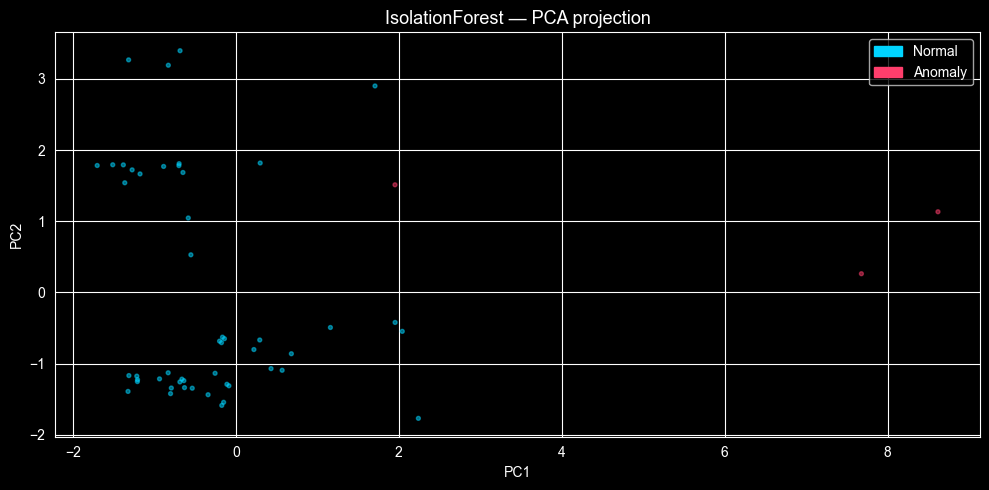

In [6]:
X_raw = df[FEATURE_COLS].fillna(0).values

scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X_raw)

iso = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
iso_preds = iso.fit_predict(X_scaled)          # -1 = anomaly, 1 = normal
iso_scores= iso.decision_function(X_scaled)    # lower = more anomalous

df["iso_label"]  = iso_preds
df["iso_score"]  = iso_scores
df["is_anomaly"] = (iso_preds == -1).astype(int)

n_anomalies = df["is_anomaly"].sum()
print(f"IsolationForest detected {n_anomalies} anomalies ({n_anomalies/len(df)*100:.1f}%)")

# ── PCA visualisation ────────────────────────────────────────────────────────
pca   = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 5))
colors = np.where(df["is_anomaly"] == 1, "#ff3e6c", "#00d4ff")
ax.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.5, s=8)
ax.set_title("IsolationForest — PCA projection", fontsize=13)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
normal_patch  = mpatches.Patch(color="#00d4ff", label="Normal")
anomaly_patch = mpatches.Patch(color="#ff3e6c", label="Anomaly")
ax.legend(handles=[normal_patch, anomaly_patch])
plt.tight_layout(); plt.show()

## 6. Neural Network — MLP Anomaly Autoencoder

In [7]:
class TransactionAutoencoder(nn.Module):
    """
    Autoencoder trained only on normal transactions.
    High reconstruction error => anomaly.
    """
    def __init__(self, input_dim: int, latent_dim: int = 8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LayerNorm(64),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.LeakyReLU(0.1),
            nn.Linear(32, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.LayerNorm(32),
            nn.LeakyReLU(0.1),
            nn.Linear(32, 64),
            nn.LayerNorm(64),
            nn.LeakyReLU(0.1),
            nn.Linear(64, input_dim),
        )

    def forward(self, x):
        z    = self.encoder(x)
        x_hat= self.decoder(z)
        return x_hat, z

    def reconstruction_error(self, x):
        x_hat, _ = self.forward(x)
        return ((x - x_hat) ** 2).mean(dim=1)

Training autoencoder on 50 normal transactions...
Architecture: 12 -> 64 -> 32 -> 8 -> 32 -> 64 -> 12
--------------------------------------------------
Epoch  10/60 | Loss: 0.536999 | LR: 0.000933
Epoch  20/60 | Loss: 0.385776 | LR: 0.000750
Epoch  30/60 | Loss: 0.280617 | LR: 0.000500
Epoch  40/60 | Loss: 0.237598 | LR: 0.000250
Epoch  50/60 | Loss: 0.229435 | LR: 0.000067
Epoch  60/60 | Loss: 0.219807 | LR: 0.000000


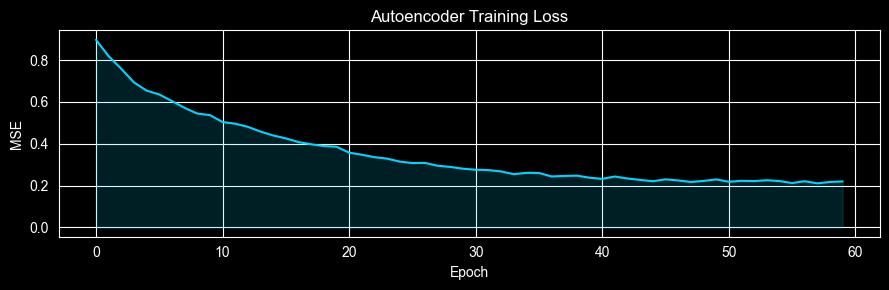

In [8]:
# ── Prepare data: train only on iso-labeled normals ──────────────────────────
X_normal = X_scaled[df["is_anomaly"] == 0]
X_tensor  = torch.tensor(X_normal, dtype=torch.float32)
dataset   = TensorDataset(X_tensor)
loader    = DataLoader(dataset, batch_size=64, shuffle=True)

INPUT_DIM   = X_scaled.shape[1]
LATENT_DIM  = 8
EPOCHS      = 60
LR          = 1e-3

autoencoder = TransactionAutoencoder(INPUT_DIM, LATENT_DIM).to(DEVICE)
optimizer   = optim.AdamW(autoencoder.parameters(), lr=LR, weight_decay=1e-5)
scheduler   = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion   = nn.MSELoss()

train_losses = []

print(f"Training autoencoder on {len(X_normal)} normal transactions...")
print(f"Architecture: {INPUT_DIM} -> 64 -> 32 -> {LATENT_DIM} -> 32 -> 64 -> {INPUT_DIM}")
print("-" * 50)

autoencoder.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    for (batch,) in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        x_hat, _ = autoencoder(batch)
        loss = criterion(x_hat, batch)
        loss.backward()
        nn.utils.clip_grad_norm_(autoencoder.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()
    avg_loss = epoch_loss / len(loader)
    train_losses.append(avg_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | Loss: {avg_loss:.6f} | LR: {scheduler.get_last_lr()[0]:.6f}")

# ── Plot training curve ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(train_losses, color="#00d4ff", linewidth=1.5)
ax.fill_between(range(len(train_losses)), train_losses, alpha=0.15, color="#00d4ff")
ax.set_title("Autoencoder Training Loss", fontsize=12)
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE")
plt.tight_layout(); plt.show()

Reconstruction error threshold (95th pct): 0.425447
Neural net flagged 6 anomalies (11.3%)


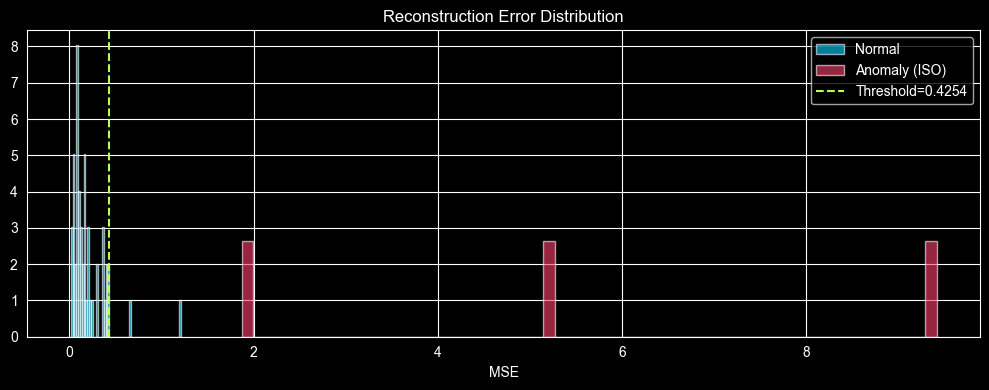

In [9]:
# ── Score all transactions ────────────────────────────────────────────────────
autoencoder.eval()
with torch.no_grad():
    X_all    = torch.tensor(X_scaled, dtype=torch.float32).to(DEVICE)
    recon_err= autoencoder.reconstruction_error(X_all).cpu().numpy()

df["recon_error"] = recon_err

# Threshold: 95th percentile of normal transactions
threshold = np.percentile(recon_err[df["is_anomaly"] == 0], 95)
df["nn_anomaly"] = (recon_err > threshold).astype(int)

print(f"Reconstruction error threshold (95th pct): {threshold:.6f}")
print(f"Neural net flagged {df['nn_anomaly'].sum()} anomalies ({df['nn_anomaly'].mean()*100:.1f}%)")

# ── Distribution plot ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(recon_err[df["is_anomaly"] == 0], bins=60, color="#00d4ff", alpha=0.6, label="Normal", density=True)
ax.hist(recon_err[df["is_anomaly"] == 1], bins=60, color="#ff3e6c", alpha=0.6, label="Anomaly (ISO)", density=True)
ax.axvline(threshold, color="#b8ff57", linestyle="--", linewidth=1.5, label=f"Threshold={threshold:.4f}")
ax.set_title("Reconstruction Error Distribution", fontsize=12)
ax.set_xlabel("MSE"); ax.legend()
plt.tight_layout(); plt.show()

## 7. Neural Network — Spending Predictor (MLP Regressor)

In [ ]:
class SpendingPredictor(nn.Module):
    """
    MLP that predicts the next transaction amount for a user.
    Input: feature vector of current transaction context.
    Output: predicted amount (log-scale).
    """
    def __init__(self, input_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [ ]:
# ── Use amount_log as regression target ───────────────────────────────────────
if "amount_log" not in df.columns:
    raise ValueError("Need 'amount' column in your data for regression target.")

REGRESSION_FEATURES = [c for c in FEATURE_COLS if c not in ["amount", "amount_log", "amount_zscore"]]
if not REGRESSION_FEATURES:
    REGRESSION_FEATURES = FEATURE_COLS[:max(1, len(FEATURE_COLS)-3)]

X_reg = df[REGRESSION_FEATURES].fillna(0).values
y_reg = df["amount_log"].fillna(0).values

scaler_reg = StandardScaler()
X_reg_sc   = scaler_reg.fit_transform(X_reg)

X_tr, X_te, y_tr, y_te = train_test_split(X_reg_sc, y_reg, test_size=0.2, random_state=42)

tr_ds  = TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32))
te_ds  = TensorDataset(torch.tensor(X_te, dtype=torch.float32), torch.tensor(y_te, dtype=torch.float32))
tr_ld  = DataLoader(tr_ds, batch_size=128, shuffle=True)
te_ld  = DataLoader(te_ds, batch_size=256)

predictor  = SpendingPredictor(X_reg_sc.shape[1]).to(DEVICE)
opt_reg    = optim.AdamW(predictor.parameters(), lr=5e-4, weight_decay=1e-4)
sched_reg  = optim.lr_scheduler.ReduceLROnPlateau(opt_reg, patience=5, factor=0.5, verbose=False)
crit_reg   = nn.HuberLoss(delta=1.0)   # robust to outliers

EPOCHS_REG = 80
tr_losses_reg, val_losses_reg = [], []

print(f"Training SpendingPredictor | features: {X_reg_sc.shape[1]} | train: {len(X_tr)} | val: {len(X_te)}")
print("-" * 55)

for epoch in range(EPOCHS_REG):
    # train
    predictor.train()
    t_loss = 0.0
    for xb, yb in tr_ld:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt_reg.zero_grad()
        pred = predictor(xb)
        loss = crit_reg(pred, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(predictor.parameters(), 1.0)
        opt_reg.step()
        t_loss += loss.item()
    t_loss /= len(tr_ld)

    # val
    predictor.eval()
    v_loss = 0.0
    with torch.no_grad():
        for xb, yb in te_ld:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            v_loss += crit_reg(predictor(xb), yb).item()
    v_loss /= len(te_ld)

    sched_reg.step(v_loss)
    tr_losses_reg.append(t_loss)
    val_losses_reg.append(v_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS_REG} | Train: {t_loss:.4f} | Val: {v_loss:.4f}")

# ── Evaluation ────────────────────────────────────────────────────────────────
predictor.eval()
with torch.no_grad():
    y_pred_log = predictor(torch.tensor(X_te, dtype=torch.float32).to(DEVICE)).cpu().numpy()

mae = mean_absolute_error(y_te, y_pred_log)
r2  = r2_score(y_te, y_pred_log)
print(f"\nTest MAE (log-scale): {mae:.4f}")
print(f"Test R²:              {r2:.4f}")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(tr_losses_reg, color="#00d4ff", label="Train", linewidth=1.5)
axes[0].plot(val_losses_reg, color="#ff3e6c", label="Val",   linewidth=1.5)
axes[0].set_title("SpendingPredictor Loss"); axes[0].legend()
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Huber Loss")

axes[1].scatter(y_te[:300], y_pred_log[:300], alpha=0.4, s=8, color="#b8ff57")
mn, mx = min(y_te.min(), y_pred_log.min()), max(y_te.max(), y_pred_log.max())
axes[1].plot([mn, mx], [mn, mx], color="#ff3e6c", linestyle="--", linewidth=1)
axes[1].set_title(f"Predicted vs Actual (R²={r2:.3f})")
axes[1].set_xlabel("Actual (log)"); axes[1].set_ylabel("Predicted (log)")

plt.tight_layout(); plt.show()

## 8. KMeans Spending Clusters

In [ ]:
# ── Elbow method ──────────────────────────────────────────────────────────────
inertias = []
K_range  = range(2, 10)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(list(K_range), inertias, marker="o", color="#00d4ff", linewidth=1.5)
ax.set_title("KMeans Elbow"); ax.set_xlabel("k"); ax.set_ylabel("Inertia")
plt.tight_layout(); plt.show()

# ── Final clustering ──────────────────────────────────────────────────────────
BEST_K = 4   # adjust after inspecting elbow
km_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
df["cluster"] = km_final.fit_predict(X_scaled)

# PCA visualisation
cluster_colors = ["#00d4ff", "#ff3e6c", "#b8ff57", "#ffaa00"]
fig, ax = plt.subplots(figsize=(9, 5))
for c in range(BEST_K):
    mask = df["cluster"] == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               s=8, alpha=0.5, color=cluster_colors[c % len(cluster_colors)], label=f"Cluster {c}")
ax.set_title("Transaction Clusters — PCA"); ax.legend(markerscale=3)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

if "amount" in df.columns:
    print(df.groupby("cluster")["amount"].describe().round(2))

## 9. Save Models

In [ ]:
import pickle, pathlib

MODEL_DIR = pathlib.Path("/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(autoencoder.state_dict(),  MODEL_DIR / "autoencoder.pt")
torch.save(predictor.state_dict(),    MODEL_DIR / "spending_predictor.pt")

with open(MODEL_DIR / "scaler.pkl",        "wb") as f: pickle.dump(scaler, f)
with open(MODEL_DIR / "scaler_reg.pkl",    "wb") as f: pickle.dump(scaler_reg, f)
with open(MODEL_DIR / "kmeans.pkl",        "wb") as f: pickle.dump(km_final, f)
with open(MODEL_DIR / "iso_forest.pkl",    "wb") as f: pickle.dump(iso, f)

print(f"All models saved to {MODEL_DIR}")

## 10. Claude AI — Financial Insights Narrative

In [ ]:
def build_summary(df: pd.DataFrame) -> dict:
    """Compile model results into a structured summary for Claude."""
    summary = {
        "total_transactions": len(df),
        "anomalies_detected": {
            "isolation_forest": int(df["is_anomaly"].sum()),
            "neural_autoencoder": int(df["nn_anomaly"].sum()),
        },
        "spending_predictor": {
            "mae_log_scale": round(float(mae), 4),
            "r2_score": round(float(r2), 4),
        },
        "clusters": {},
    }
    if "amount" in df.columns:
        for c in range(BEST_K):
            grp = df[df["cluster"] == c]["amount"]
            summary["clusters"][f"cluster_{c}"] = {
                "count": len(grp),
                "mean_amount": round(float(grp.mean()), 2),
                "median_amount": round(float(grp.median()), 2),
                "std_amount": round(float(grp.std()), 2),
            }
    return summary


def get_claude_insights(summary: dict) -> str:
    prompt = f"""You are a senior financial AI analyst for FinScope-Ai, a personal finance intelligence platform.

The following is a structured summary of a neural network analysis run on a user's transaction history:

{json.dumps(summary, indent=2)}

Write a clear, insightful financial intelligence report covering:
1. Anomaly findings — what the dual-model anomaly detection reveals and what the user should investigate
2. Spending prediction quality — interpret the R² and MAE in plain English
3. Cluster analysis — characterise each spending cluster and name them meaningfully (e.g. "Essential Bills", "Impulse Spend")
4. 3 concrete, actionable recommendations for the user

Tone: professional but human. No bullet soup — use short paragraphs. Be specific."""

    response = claude.messages.create(
        model="claude-sonnet-4-20250514",
        max_tokens=1024,
        messages=[{"role": "user", "content": prompt}]
    )
    return response.content[0].text


summary = build_summary(df)
print("=" * 60)
print("FINSCOPE-AI — NEURAL NETWORK INTELLIGENCE REPORT")
print("=" * 60)
insights = get_claude_insights(summary)
print(insights)

## 11. Write Insights Back to Supabase

In [ ]:
def push_insights_to_supabase(summary: dict, narrative: str, table: str = "ai_insights"):
    """
    Push model results and Claude narrative back to Supabase.
    Adjust `table` to match your schema.
    """
    payload = {
        "created_at":  datetime.utcnow().isoformat(),
        "model_type":  "neural_network_pipeline",
        "summary":     json.dumps(summary),
        "narrative":   narrative,
        "anomaly_count": summary["anomalies_detected"]["neural_autoencoder"],
        "r2_score":    summary["spending_predictor"]["r2_score"],
    }
    response = supabase.table(table).insert(payload).execute()
    print(f"Pushed to Supabase table '{table}': {response.data}")


# Uncomment when your `ai_insights` table exists:
# push_insights_to_supabase(summary, insights)